# NASA C-MAPSS FD004 - Remaining Useful Life (RUL) prediction

This notebook covers the whole modelling pipeline: feature engineering, model selection, hyperparameter tuning, final evaluation on the official test set and model export.

## Feature engineering methodology

In the first phase new features and/or transformations are tested to see whether they add information to a base model. For every addition and/or transformation, a CV on the training set is run, training a Random Forest with default hyperparameters.

## Target definition

The EDA (moving average per operating condition) showed that sensors start degrading around a RUL of 125, while they remain mostly constant in the earlier phases. The target is therefore clipped: 

$$
\mathrm{RUL}_{\text{target}} =
\begin{cases}
125 & \text{if } \mathrm{RUL} \ge 125, \\
\mathrm{RUL} & \text{if } \mathrm{RUL} < 125.
\end{cases}
$$

In this way the model focuses mostly on the degradation phase rather than on the initial one, keeping in mind the goal of the final model: recognise when an engine is in the degradation phase and needs preventive maintenance.

## NASA Score

To complement standard regression metrics such as RMSE and MAE, this work also adopts the **NASA Score**, a performance metric specifically designed for Remaining Useful Life (RUL) prediction. Unlike symmetric error measures, the NASA Score applies an asymmetric penalty: **late predictions** (overestimating the remaining life of a component) are penalized more heavily than **early predictions**, since they may lead to unexpected failures and have more severe consequences in real world maintenance scenarios.

For each prediction, the error is defined as:

$$
d_i = \hat{RUL}_i - RUL_i
$$

The score is then computed as:

$$
S =
\sum_{i=1}^{N}
\begin{cases}
e^{-d_i/13} - 1, & d_i < 0, \\
e^{d_i/10} - 1, & d_i \ge 0.
\end{cases}
$$

where:

* $\hat{RUL}_i$ is the predicted Remaining Useful Life,
* $RUL_i$ is the true Remaining Useful Life,
* $N$ is the number of samples.

## 1. Import and configuration

Libraries are imported here. Global constants (seed, number of folds, RUL cap, column names, thresholds) and the reusable functions live in `../src`, so that the notebook, the cross-validation and the inference code use exactly the same definitions:

* `config.py`: constants and feature lists;
* `preprocessing.py`: operating-condition clustering, per-condition normalisation, deviation from the initial state, removal of constant features;
* `evaluation.py`: engine-based folds, NASA score and cross-validation of an estimator.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import ParameterSampler

# Project modules (the notebook lives in notebooks/, the modules in src/)
sys.path.append("../src")

from config import (
    CANDIDATE_FEATURES,
    COND,
    CONSTANT_STD,
    CYCLE,
    DEV_COLS,
    DROP_COLS,
    K0,
    N_COND,
    N_ITER,
    RUL,
    RUL_CAP,
    SEED,
    SENSOR_COLS,
    UNIT,
)
from evaluation import cv_evaluate, get_fold, make_folds, nasa_score
from preprocessing import (
    add_cond,
    add_deviation,
    apply_cond_norm,
    fit_cond_model,
    fit_cond_stats,
    select_non_constant,
)

# Base model used in the feature engineering experiments
model = RandomForestRegressor(random_state=SEED, n_jobs=-1)

pd.set_option("display.max_columns", None)

## 2. Load training set and build the target

The training set contains run-to-failure trajectories, so the RUL of each row is the number of cycles left before the last recorded cycle of its engine. It is then clipped at 125 (see above). The test set is loaded only in the final evaluation (section 11), so that it cannot influence any modelling decision.

In [2]:
df = pd.read_csv("../data/csv/train.csv", sep=",")

# Target: cycles left before the last cycle of the engine, clipped at RUL_CAP
max_cycles = df.groupby(UNIT)[CYCLE].transform("max")
df[RUL] = (max_cycles - df[CYCLE]).clip(upper=RUL_CAP)

## 3. Fold generation

Folds are generated on the engine IDs, not on the rows: rows from the same engine are strongly correlated, so splitting them between train and validation would leak information and make the CV estimate overly optimistic. The same folds are reused in every experiment (feature engineering, model selection and tuning), so that all the results are directly comparable.

In [3]:
folds = make_folds(df)

## 4. Baseline

Reference point: a Random Forest with default hyperparameters trained on all the raw columns (sensors, operational settings and cycle). Every new feature or transformation is judged against this result (mean RMSE and mean nasa score over the 5 folds).

In [4]:
features = [c for c in df.columns if c not in DROP_COLS]

# Cross-validation over engine-based folds
fold_results = []
for i, (tr_units, val_units) in enumerate(folds, 1):
    train_df, val_df = get_fold(df, tr_units, val_units)

    X_train, y_train = train_df[features], train_df[RUL]
    X_val, y_val = val_df[features], val_df[RUL]

    m = clone(model)
    m.fit(X_train, y_train)
    pred = m.predict(X_val)

    fold_results.append({
        "fold": i,
        "n_train_units": len(tr_units),
        "n_val_units": len(val_units),
        "rmse": root_mean_squared_error(y_val, pred),
        "mae": mean_absolute_error(y_val, pred),
        "r2": r2_score(y_val, pred),
        "nasa_score": nasa_score(y_val, pred, reduce="mean")
    })

results = pd.DataFrame(fold_results)
print(results)
print(results[["rmse", "mae", "r2", "nasa_score"]].agg(["mean", "std"]))

   fold  n_train_units  n_val_units       rmse        mae        r2  \
0     1            199           50  19.676305  13.009455  0.768290   
1     2            199           50  16.114695  10.541852  0.843256   
2     3            199           50  16.792289  10.341336  0.827974   
3     4            199           50  15.983275  10.554332  0.847016   
4     5            200           49  14.722603  10.114144  0.866995   

   nasa_score  
0   10.403440  
1    7.765322  
2   25.981418  
3    7.141099  
4    3.831703  
           rmse        mae        r2  nasa_score
mean  16.657833  10.912224  0.830706   11.024596
std    1.845562   1.186011  0.037562    8.682374


## 5. Normalisation by operating condition

The operating conditions are defined with KMeans and the corresponding one is assigned to each row of the dataset. Since the sensors are normalised by operating condition, the operational settings can be dropped from the features, as their information is now intrinsically embedded in the sensors. To avoid data leakage, the normalisation uses only statistics computed on the training portion of each fold, and these same statistics are applied to the validation portion (they are never recomputed on it). As this is only a normalisation, neither an improvement nor a worsening of the performance is expected.

In [5]:
cond_model = fit_cond_model(df)
df = add_cond(df, cond_model)

print(df[COND].value_counts().sort_index())   # there must be 6 groups

cond
0    15395
1     9224
2     9139
3     9091
4     9238
5     9162
Name: count, dtype: int64


In [6]:
df.head()

,unit number,cycle,operational setting 1,operational setting 2,operational setting 3,sensor1,sensor2,sensor3,sensor4,sensor5,sensor6,sensor7,sensor8,sensor9,sensor10,sensor11,sensor12,sensor13,sensor14,sensor15,sensor16,sensor17,sensor18,sensor19,sensor20,sensor21,rul,cond
0,1,1,42.0049,0.8400,100.0,445.00,549.68,1343.43,1112.93,3.91,5.70,137.36,2211.86,8311.32,1.01,41.69,129.78,2387.99,8074.83,9.3335,0.02,330,2212,100.00,10.62,6.3670,125,0
1,1,2,20.0020,0.7002,100.0,491.19,606.07,1477.61,1237.50,9.35,13.61,332.10,2323.66,8713.60,1.07,43.94,312.59,2387.73,8046.13,9.1913,0.02,361,2324,100.00,24.37,14.6552,125,3
2,1,3,42.0038,0.8409,100.0,445.00,548.95,1343.12,1117.05,3.91,5.69,138.18,2211.92,8306.69,1.01,41.66,129.62,2387.97,8066.62,9.4007,0.02,329,2212,100.00,10.48,6.4213,125,0
3,1,4,42.0000,0.8400,100.0,445.00,548.70,1341.24,1118.03,3.91,5.70,137.98,2211.88,8312.35,1.02,41.68,129.80,2388.02,8076.05,9.3369,0.02,328,2212,100.00,10.54,6.4176,125,0
4,1,5,25.0063,0.6207,60.0,462.54,536.10,1255.23,1033.59,7.05,9.00,174.82,1915.22,7994.94,0.93,36.48,164.11,2028.08,7865.80,10.8366,0.02,305,1915,84.93,14.03,8.6754,125,2


In [7]:
fold_results = []
for i, (tr_units, val_units) in enumerate(folds, 1):
    train_df, val_df = get_fold(df, tr_units, val_units)

    mean, std = fit_cond_stats(train_df)          # fit ONLY on the train set
    train_df = apply_cond_norm(train_df, mean, std)
    val_df = apply_cond_norm(val_df, mean, std)   # same statistics

    features = SENSOR_COLS + [CYCLE]

    X_train, y_train = train_df[features], train_df[RUL]
    X_val, y_val = val_df[features], val_df[RUL]

    m = clone(model)
    m.fit(X_train, y_train)
    pred = m.predict(X_val)

    fold_results.append({
        "fold": i,
        "n_train_units": len(tr_units),
        "n_val_units": len(val_units),
        "rmse": root_mean_squared_error(y_val, pred),
        "mae": mean_absolute_error(y_val, pred),
        "r2": r2_score(y_val, pred),
        "nasa_score": nasa_score(y_val, pred, reduce="mean")
    })

results = pd.DataFrame(fold_results)
print(results)
print(results[["rmse", "mae", "r2", "nasa_score"]].agg(["mean", "std"]))

   fold  n_train_units  n_val_units       rmse        mae        r2  \
0     1            199           50  19.367953  12.791712  0.775495   
1     2            199           50  15.819936  10.302693  0.848937   
2     3            199           50  16.756096  10.346065  0.828715   
3     4            199           50  15.858767  10.464514  0.849390   
4     5            200           49  14.689871  10.003197  0.867585   

   nasa_score  
0    9.527437  
1    7.271567  
2   22.912732  
3    7.193473  
4    4.077464  
           rmse        mae        r2  nasa_score
mean  16.498525  10.781636  0.834025   10.196535
std    1.763587   1.136447  0.035492    7.368280


As expected, the results are essentially unchanged.

## 6. Rolling mean and std

Causal moving average and standard deviation (window of 10 cycles) of each sensor, computed separately for each engine. The idea is to give the model a smoothed view of the sensor trend and of its local variability.

In [8]:
WINDOW = 10

def add_rolling(df, sensor_cols=SENSOR_COLS, window=WINDOW):
    """Causal rolling mean and std per engine. Sorts by (unit, cycle)."""
    out = df.sort_values([UNIT, CYCLE]).copy()
    roll = out.groupby(UNIT)[sensor_cols].rolling(window, min_periods=1)

    mean = roll.mean().reset_index(level=0, drop=True).add_suffix(f"_mean{window}")
    std = roll.std().reset_index(level=0, drop=True).add_suffix(f"_std{window}")

    out = out.join(mean).join(std)
    std_cols = [f"{c}_std{window}" for c in sensor_cols]
    out[std_cols] = out[std_cols].fillna(0)   # first row of each engine: std is undefined
    return out

In [9]:
fold_results = []
for i, (tr_units, val_units) in enumerate(folds, 1):
    train_df, val_df = get_fold(df, tr_units, val_units)

    mean, std = fit_cond_stats(train_df)          # fit ONLY on the train set
    train_df = apply_cond_norm(train_df, mean, std)
    val_df = apply_cond_norm(val_df, mean, std)   # same statistics

    train_df = add_rolling(train_df)
    val_df = add_rolling(val_df)

    ROLL_COLS = [f"{c}_{s}{WINDOW}" for c in SENSOR_COLS for s in ("mean", "std")]
    features = SENSOR_COLS + [CYCLE] + ROLL_COLS

    X_train, y_train = train_df[features], train_df[RUL]
    X_val, y_val = val_df[features], val_df[RUL]

    m = clone(model)
    m.fit(X_train, y_train)
    pred = m.predict(X_val)

    fold_results.append({
        "fold": i,
        "n_train_units": len(tr_units),
        "n_val_units": len(val_units),
        "rmse": root_mean_squared_error(y_val, pred),
        "mae": mean_absolute_error(y_val, pred),
        "r2": r2_score(y_val, pred),
        "nasa_score": nasa_score(y_val, pred, reduce="mean")
    })

results = pd.DataFrame(fold_results)
print(results)
print(results[["rmse", "mae", "r2", "nasa_score"]].agg(["mean", "std"]))

   fold  n_train_units  n_val_units       rmse        mae        r2  \
0     1            199           50  19.652244  12.697677  0.768856   
1     2            199           50  15.722225   9.901025  0.850798   
2     3            199           50  17.096635  10.196433  0.821682   
3     4            199           50  15.908113  10.295787  0.848452   
4     5            200           49  14.687967   9.663367  0.867620   

   nasa_score  
0   10.557813  
1    7.898087  
2   27.508556  
3    7.040264  
4    4.044189  
           rmse        mae        r2  nasa_score
mean  16.613437  10.550858  0.831481   11.409782
std    1.901776   1.225707  0.038682    9.294797


These features do not bring any improvement, so they are discarded.

## 7. Deviation from the initial state

For each engine a baseline is computed as the mean of each sensor over its first 10 cycles, and it is subtracted from every row of that engine. This captures how far an engine has drifted from its own healthy state, regardless of the engine-to-engine differences in initial wear.

In [10]:
features = SENSOR_COLS + [CYCLE] + DEV_COLS

fold_results = []
for i, (tr_units, val_units) in enumerate(folds, 1):
    train_df, val_df = get_fold(df, tr_units, val_units)

    mean, std = fit_cond_stats(train_df)          # fit ONLY on the train set
    train_df = apply_cond_norm(train_df, mean, std)
    val_df = apply_cond_norm(val_df, mean, std)   # same statistics

    train_df = add_deviation(train_df)
    val_df = add_deviation(val_df)

    X_train, y_train = train_df[features], train_df[RUL]
    X_val, y_val = val_df[features], val_df[RUL]

    m = clone(model)
    m.fit(X_train, y_train)
    pred = m.predict(X_val)

    fold_results.append({
        "fold": i,
        "n_train_units": len(tr_units),
        "n_val_units": len(val_units),
        "rmse": root_mean_squared_error(y_val, pred),
        "mae": mean_absolute_error(y_val, pred),
        "r2": r2_score(y_val, pred),
        "nasa_score": nasa_score(y_val, pred, reduce="mean")
    })

results = pd.DataFrame(fold_results)
print(results)
print(results[["rmse", "mae", "r2", "nasa_score"]].agg(["mean", "std"]))

   fold  n_train_units  n_val_units       rmse        mae        r2  \
0     1            199           50  16.523811  10.767496  0.836590   
1     2            199           50  13.468149   8.634287  0.890513   
2     3            199           50  16.024228   9.175778  0.843351   
3     4            199           50  12.742287   8.410994  0.902768   
4     5            200           49  12.487798   8.316946  0.904309   

   nasa_score  
0    6.072385  
1    3.989330  
2   27.298408  
3    3.070801  
4    2.998081  
           rmse       mae        r2  nasa_score
mean  14.249255  9.061100  0.875506    8.685801
std    1.891292  1.010385  0.032964   10.478481


These features do bring information. They are kept.

## 8. Feature selection

Sensors that are (almost) constant carry no information. Features whose standard deviation, computed on the training portion of the fold, is below a threshold are removed. The selection is repeated inside each fold, so that it never uses validation data.

In [11]:
fold_results = []
for i, (tr_units, val_units) in enumerate(folds, 1):
    train_df, val_df = get_fold(df, tr_units, val_units)

    cond_mean, cond_std = fit_cond_stats(train_df)
    train_df = apply_cond_norm(train_df, cond_mean, cond_std)
    val_df = apply_cond_norm(val_df, cond_mean, cond_std)

    train_df = add_deviation(train_df)
    val_df = add_deviation(val_df)

    # Feature selection: std computed ONLY on the train set of the fold
    features = select_non_constant(train_df, CANDIDATE_FEATURES)
    dropped = sorted(set(CANDIDATE_FEATURES) - set(features))
    print(f"fold {i}: dropped {len(dropped)} features -> {dropped}")

    X_train, y_train = train_df[features], train_df[RUL]
    X_val, y_val = val_df[features], val_df[RUL]

    m = clone(model)
    m.fit(X_train, y_train)
    pred = m.predict(X_val)

    fold_results.append({
        "fold": i,
        "n_train_units": len(tr_units),
        "n_val_units": len(val_units),
        "rmse": root_mean_squared_error(y_val, pred),
        "mae": mean_absolute_error(y_val, pred),
        "r2": r2_score(y_val, pred),
        "nasa_score": nasa_score(y_val, pred, reduce="mean")
    })

results = pd.DataFrame(fold_results)
print(results)
print(results[["rmse", "mae", "r2", "nasa_score"]].agg(["mean", "std"]))

fold 1: dropped 8 features -> ['sensor1', 'sensor18', 'sensor18_dev', 'sensor19', 'sensor19_dev', 'sensor1_dev', 'sensor5', 'sensor5_dev']
fold 2: dropped 8 features -> ['sensor1', 'sensor18', 'sensor18_dev', 'sensor19', 'sensor19_dev', 'sensor1_dev', 'sensor5', 'sensor5_dev']
fold 3: dropped 8 features -> ['sensor1', 'sensor18', 'sensor18_dev', 'sensor19', 'sensor19_dev', 'sensor1_dev', 'sensor5', 'sensor5_dev']
fold 4: dropped 8 features -> ['sensor1', 'sensor18', 'sensor18_dev', 'sensor19', 'sensor19_dev', 'sensor1_dev', 'sensor5', 'sensor5_dev']
fold 5: dropped 8 features -> ['sensor1', 'sensor18', 'sensor18_dev', 'sensor19', 'sensor19_dev', 'sensor1_dev', 'sensor5', 'sensor5_dev']
   fold  n_train_units  n_val_units       rmse        mae        r2  \
0     1            199           50  16.506628  10.763058  0.836930   
1     2            199           50  13.451825   8.627974  0.890778   
2     3            199           50  16.021777   9.177343  0.843398   
3     4            19

The result is practically identical, so these features are permanently removed. The same 8 features are dropped in every fold: sensor1, sensor5, sensor18, sensor19 and their deviation counterparts.

## 9. Model selection

Three models (Random Forest, Extra Trees and HistGradientBoosting) are compared with default hyperparameters on the same folds. The whole preprocessing (normalisation, deviation, feature selection) is refitted inside each fold. In the CV the NASA score is averaged over the rows, so it is not directly comparable with the NASA score on the test set, which is summed over the last cycle of each engine.

In [12]:
models = {
    "rf": RandomForestRegressor(random_state=SEED, n_jobs=-1),
    "et": ExtraTreesRegressor(random_state=SEED, n_jobs=-1),
    "hgb": HistGradientBoostingRegressor(random_state=SEED),
}

# Compare the models with default hyperparameters on the same folds
comparison = {}
for name, est in models.items():
    res = cv_evaluate(est, df, folds)
    comparison[name] = res[["rmse", "mae", "r2", "nasa_score"]].agg(["mean", "std"]).stack()
    print(f"{name}: rmse={res['rmse'].mean():.3f} ± {res['rmse'].std():.3f} | "
          f"nasa={res['nasa_score'].mean():.3f} ± {res['nasa_score'].std():.3f}")

comparison_df = pd.DataFrame(comparison).T
print(comparison_df)

rf: rmse=14.241 ± 1.888 | nasa=8.692 ± 10.515
et: rmse=14.025 ± 1.896 | nasa=8.327 ± 10.130
hgb: rmse=14.000 ± 1.888 | nasa=9.180 ± 11.845
          mean                                      std                      \
          rmse       mae        r2 nasa_score      rmse       mae        r2   
rf   14.241042  9.056708  0.875652   8.692125  1.888109  1.011282  0.032898   
et   14.024684  9.072974  0.879334   8.326847  1.896001  1.011203  0.032562   
hgb  14.000171  8.863167  0.879760   9.179739  1.888060  0.881227  0.032309   

                
    nasa_score  
rf   10.515129  
et   10.130325  
hgb  11.844967  


Making a trade-off between all the metrics, with particular attention to the NASA score, ExtraTreesRegressor is chosen as the best model. The differences in RMSE between the three models (about 0.2) are well within the fold-to-fold variability (std of about 1.9), so this is a trade-off rather than a clear win.

In [13]:
best_name = "et"
print("\nSelected model:", best_name)


Selected model: et


## 10. Hyperparameter tuning

Randomised search (20 random combinations) on the selected model only, evaluated with the same CV. The best configuration is the one with the lowest mean RMSE across the folds. The test set is still untouched. The gain over the default hyperparameters is small (mean RMSE of about 13.96 against 14.02).

In [14]:
param_spaces = {
    "rf": {
        "n_estimators": randint(100, 400),
        "max_depth": randint(8, 30),
        "min_samples_leaf": randint(1, 30),
        "max_features": uniform(0.3, 0.7),
    },
    "et": {
        "n_estimators": randint(100, 400),
        "max_depth": randint(8, 30),
        "min_samples_leaf": randint(1, 30),
        "max_features": uniform(0.3, 0.7),
    },
    "hgb": {
        "learning_rate": loguniform(0.01, 0.3),
        "max_iter": randint(100, 600),
        "max_depth": randint(3, 12),
        "min_samples_leaf": randint(20, 200),
        "l2_regularization": loguniform(1e-3, 10),
    },
}

# Random search: each sampled configuration is evaluated with the same CV
tuning_results = []
for j, params in enumerate(ParameterSampler(param_spaces[best_name], n_iter=N_ITER, random_state=SEED), 1):
    res = cv_evaluate(clone(models[best_name]).set_params(**params), df, folds)
    tuning_results.append({
        "params": params,
        "rmse": res["rmse"].mean(),
        "rmse_std": res["rmse"].std(),
        "mae": res["mae"].mean(),
        "r2": res["r2"].mean(),
        "nasa_score": res["nasa_score"].mean(),
        "nasa_std": res["nasa_score"].std(),
    })
    print(f"[{j}/{N_ITER}] rmse={res['rmse'].mean():.3f} nasa={res['nasa_score'].mean():.3f}")

# Best configuration = lowest mean RMSE
tuning_df = pd.DataFrame(tuning_results).sort_values("rmse").reset_index(drop=True)
best_params = tuning_df.loc[0, "params"]
print(tuning_df.drop(columns="params").head())
print("Best hyperparameters:", best_params)

[1/20] rmse=14.413 nasa=8.619
[2/20] rmse=14.281 nasa=8.622
[3/20] rmse=14.458 nasa=8.480
[4/20] rmse=14.527 nasa=8.477
[5/20] rmse=14.704 nasa=8.512
[6/20] rmse=15.300 nasa=9.257
[7/20] rmse=14.577 nasa=8.504
[8/20] rmse=14.256 nasa=8.453
[9/20] rmse=14.478 nasa=8.487
[10/20] rmse=14.545 nasa=8.504
[11/20] rmse=14.661 nasa=8.796
[12/20] rmse=14.517 nasa=8.510
[13/20] rmse=14.609 nasa=8.508
[14/20] rmse=15.017 nasa=9.121
[15/20] rmse=14.572 nasa=8.521
[16/20] rmse=14.222 nasa=8.657
[17/20] rmse=14.592 nasa=8.509
[18/20] rmse=13.959 nasa=8.381
[19/20] rmse=14.727 nasa=8.903
[20/20] rmse=14.600 nasa=8.576
        rmse  rmse_std       mae        r2  nasa_score   nasa_std
0  13.958514  1.942655  8.976206  0.880370    8.380537  10.168865
1  14.221890  1.881413  9.254073  0.876001    8.657473   9.932265
2  14.256093  1.847489  9.290791  0.875475    8.453305   9.623866
3  14.280577  1.860125  9.342565  0.875029    8.622337   9.719744
4  14.412860  1.814386  9.465841  0.872817    8.618759   9.

## 11. Final evaluation on the test set

The best configuration is refitted on the whole training set (the preprocessing statistics and the feature selection are recomputed on it) and evaluated once on the test set. As in the official benchmark, only the last observed cycle of each test engine is used, and the true RUL (also clipped at 125) is provided by a separate file. The preprocessing is applied to the full history of each test engine before taking its last row, because the deviation features need the first cycles of the engine.

In [15]:
# Test set and true RUL of each test engine
test_df = pd.read_csv("../data/csv/test.csv", sep=",")
test_df = add_cond(test_df, cond_model)

# True RUL: one value per engine, in the same order as the unit numbers
rul_test = pd.read_csv("../data/raw/RUL_FD004.txt", header=None)[0].clip(upper=RUL_CAP)
rul_test.index = np.sort(test_df[UNIT].unique())

# Preprocessing with the statistics of the whole training set, applied to the FULL test history
cond_mean, cond_std = fit_cond_stats(df)
train_full = add_deviation(apply_cond_norm(df, cond_mean, cond_std))
test_full = add_deviation(apply_cond_norm(test_df, cond_mean, cond_std))

features = select_non_constant(train_full, CANDIDATE_FEATURES)

# Refit the best configuration on the whole training set
final_model = clone(models[best_name]).set_params(**best_params)
final_model.fit(train_full[features], train_full[RUL])

# Only now: keep the last row (last cycle) of each test engine
last_idx = test_full.groupby(UNIT)[CYCLE].idxmax()
test_last = test_full.loc[last_idx].set_index(UNIT).sort_index()

assert len(test_last) == len(rul_test) == test_df[UNIT].nunique()
y_true = rul_test.loc[test_last.index].to_numpy()
y_pred = final_model.predict(test_last[features])

test_metrics = {
    "rmse": root_mean_squared_error(y_true, y_pred),
    "mae": mean_absolute_error(y_true, y_pred),
    "r2": r2_score(y_true, y_pred),
    "nasa_score": nasa_score(y_true, y_pred, reduce="sum"),   # sum over the engines
}
print(test_metrics)

{'rmse': 14.747079083526522, 'mae': 10.315628659605075, 'r2': 0.8822784555916183, 'nasa_score': 1210.6143451704284}


### Metrics against the original (not clipped) RUL, for reference

In [23]:
rul_raw = pd.read_csv("../data/raw/RUL_FD004.txt", header=None)[0]
rul_raw.index = np.sort(test_df[UNIT].unique())
y_true_raw = rul_raw.loc[test_last.index].to_numpy()

above_cap = y_true_raw > RUL_CAP
print(f"Engines with true RUL > {RUL_CAP}: {above_cap.sum()} / {len(y_true_raw)}")

print("Original RUL, all engines:", {
    "rmse": round(root_mean_squared_error(y_true_raw, y_pred), 2),
    "nasa_score": round(nasa_score(y_true_raw, y_pred), 1),
})

# Diagnostic only: selecting engines by their true RUL is not possible in production
print(f"Original RUL, engines with true RUL <= {RUL_CAP}:", {
    "rmse": round(root_mean_squared_error(y_true_raw[~above_cap], y_pred[~above_cap]), 2),
    "nasa_score": round(nasa_score(y_true_raw[~above_cap], y_pred[~above_cap]), 1),
})

Engines with true RUL > 125: 67 / 248
Original RUL, all engines: {'rmse': 26.94, 'nasa_score': 5058.9}
Original RUL, engines with true RUL <= 125: {'rmse': 14.97, 'nasa_score': 1029.9}


## 12. Error analysis

Predicted vs true RUL and distribution of the errors (predicted - true) on the last cycle of each test engine, shown twice: against the clipped RUL, which is the one used for the evaluation, and against the original RUL, for reference. Positive errors are overestimations of the RUL, which are the most costly ones, since the engine would fail earlier than predicted.

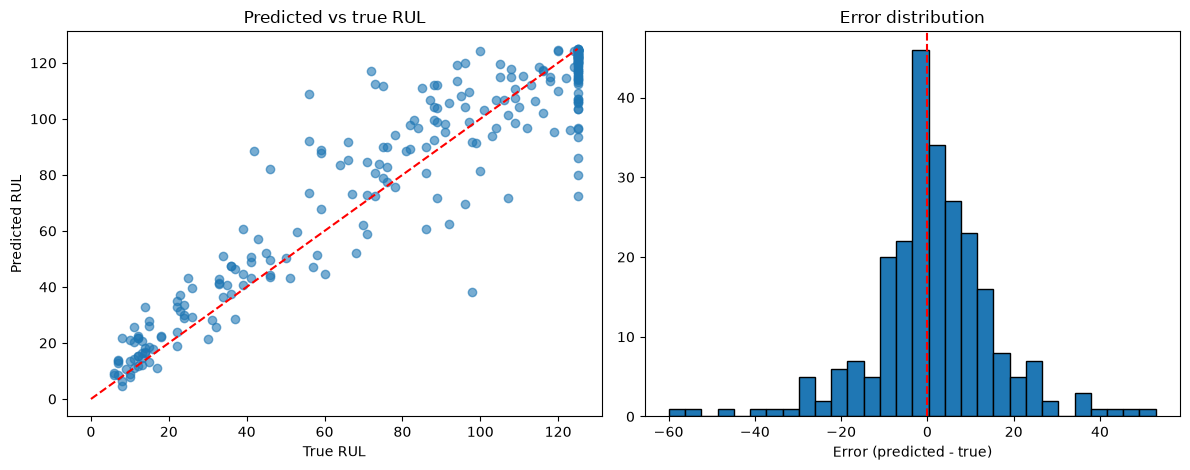

In [21]:
err = y_pred - y_true   # positive = overestimation of the RUL

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))

# Predicted vs true RUL
ax[0].scatter(y_true, y_pred, alpha=0.6)
ax[0].plot([0, RUL_CAP], [0, RUL_CAP], "r--")
ax[0].set(xlabel="True RUL", ylabel="Predicted RUL", title="Predicted vs true RUL")

# Error distribution
ax[1].hist(err, bins=30, edgecolor="k")
ax[1].axvline(0, color="r", ls="--")
ax[1].set(xlabel="Error (predicted - true)", title="Error distribution")

plt.tight_layout()
plt.show()

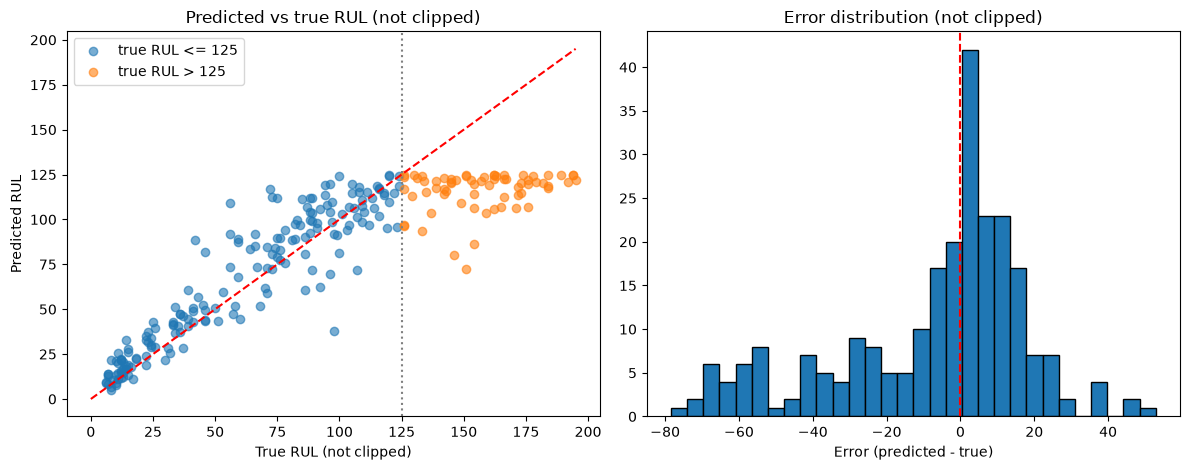

In [22]:
# True (not clipped) RUL of each test engine
rul_raw = pd.read_csv("../data/raw/RUL_FD004.txt", header=None)[0]
rul_raw.index = np.sort(test_df[UNIT].unique())
y_true_raw = rul_raw.loc[test_last.index].to_numpy()
err_raw = y_pred - y_true_raw   # positive = overestimation of the RUL
above_cap = y_true_raw > RUL_CAP

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))

# Predicted vs true RUL (not clipped)
ax[0].scatter(y_true_raw[~above_cap], y_pred[~above_cap], alpha=0.6, label=f"true RUL <= {RUL_CAP}")
ax[0].scatter(y_true_raw[above_cap], y_pred[above_cap], alpha=0.6, label=f"true RUL > {RUL_CAP}")
ax[0].plot([0, y_true_raw.max()], [0, y_true_raw.max()], "r--")
ax[0].axvline(RUL_CAP, color="gray", ls=":")
ax[0].set(xlabel="True RUL (not clipped)", ylabel="Predicted RUL",
          title="Predicted vs true RUL (not clipped)")
ax[0].legend()

# Error distribution
ax[1].hist(err_raw, bins=30, edgecolor="k")
ax[1].axvline(0, color="r", ls="--")
ax[1].set(xlabel="Error (predicted - true)", title="Error distribution (not clipped)")

plt.tight_layout()
plt.show()

## 13. Save the model

The fitted model is exported together with all the artefacts needed at inference time: the operating-condition model, the normalisation statistics, the final list of features and the configuration.

In [24]:
MODEL_PATH = Path("../models/extra_trees_fd004.joblib")
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)


def compute_metrics(y_true, y_pred):
    """Test metrics on the last cycle of each engine (NASA score summed over the engines)."""
    return {
        "rmse": root_mean_squared_error(y_true, y_pred),
        "mae": mean_absolute_error(y_true, y_pred),
        "r2": r2_score(y_true, y_pred),
        "nasa_score": nasa_score(y_true, y_pred),
    }


artifact = {
    "model": final_model,
    "model_name": best_name,
    "best_params": best_params,
    "features": features,            # final feature list, in training order
    "cond_model": cond_model,        # KMeans pipeline for the operating conditions
    "cond_mean": cond_mean,          # per-condition sensor means (whole training set)
    "cond_std": cond_std,            # per-condition sensor stds (whole training set)
    "sensor_cols": SENSOR_COLS,
    "config": {
        "rul_cap": RUL_CAP,
        "k0": K0,
        "n_cond": N_COND,
        "constant_std": CONSTANT_STD,
        "seed": SEED,
    },
    "test_metrics": {
        "clipped_rul": compute_metrics(y_true, y_pred),        # used for the evaluation
        "original_rul": compute_metrics(y_true_raw, y_pred),   # for reference, not comparable
    },
}

joblib.dump(artifact, MODEL_PATH)

size_mb = MODEL_PATH.stat().st_size / 1e6
print(f"Model saved to {MODEL_PATH.as_posix()} ({size_mb:.1f} MB)")

Model saved to ../models/extra_trees_fd004.joblib (717.6 MB)


## 14. Conclusions

**Choices made along the way.** All the experiments were evaluated on the same engine-based CV folds. Normalising the sensors by operating condition left the results essentially unchanged, rolling mean and std did not help, while the deviation from the initial state of each engine brought a clear improvement and was kept; constant features were removed. Random Forest, Extra Trees and HistGradientBoosting performed similarly, and Extra Trees was chosen as a compromise between RMSE and NASA score. Hyperparameter tuning brought only a small gain.

**Clipped RUL.** From the start the target was clipped at 125 cycles, and both the validation folds and the test set were evaluated against the clipped RUL. The aim was to focus the evaluation on the degradation phase rather than on the long healthy phase, where telling a RUL of 150 from 300 is hard and weighs heavily on the error. On the test set this gives RMSE ≈ 14.8 and NASA score ≈ 1,210. For reference, against the original RUL the same predictions give RMSE ≈ 26.9 and NASA score ≈ 5,059: they are higher because 67 of the 248 test engines have a true RUL above 125, and the two sets of numbers are not comparable.

**Possible use with real data.** With real data the RUL is not clipped, but the model keeps predicting values capped at about 125. A predicted RUL below 125 indicates that the engine has entered the degradation phase and may need preventive maintenance, while a prediction close to 125 indicates that it is still in the healthy phase. The model can therefore be used almost as a classifier: *does this engine need maintenance?*

**Plots.**
- *Predicted vs true RUL (clipped)*: the closer the points are to the diagonal, the better the prediction; the vertical column at 125 collects the engines that are still healthy.
- *Predicted vs true RUL (original)*: the engines with a true RUL above 125 form a band below the diagonal, because the prediction cannot exceed about 125.
- *Error distribution* (predicted - true): positive errors are overestimations, the ones the NASA score penalises most; with the original RUL the negative tail is inflated by the engines above 125.